# Chapter 5 · Backtesting

*Book 21 · Time Series · Shelf V*

**Builds on:** [Chapter 4](04-arima-and-sarima.ipynb) (a forecast on one window), and
cross-validation from book 20.
**You will:** watch a shuffled split flatter a model, evaluate on expanding windows instead,
and report a score the honest way: next to a baseline, with an interval.

Chapter 4 ended on one four-week window. A different four weeks would have given a different
verdict. A **backtest** replays history: stand at many past moments, fit on what was known
then, forecast what came next, and score every one.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import KFold, cross_val_score
from statsmodels.tsa.statespace.sarimax import SARIMAX

from ds_toolbox import baselines, io, viz
from ds_toolbox import evaluation as ev

viz.use_style()
warnings.filterwarnings("ignore", category=UserWarning)

raw = io.load_sample("ewz_zurich_hourly.csv.gz")
daily = (raw.assign(t=pd.to_datetime(raw["hour_utc"], utc=True)).set_index("t")["total_mwh"]
         .tz_convert("Europe/Zurich").resample("D").mean().tz_localize(None).asfreq("D")).iloc[1:-1]

## A shuffled split lies

Take a model that only knows the calendar -- the day of the year, the weekday and the year --
and estimate its error two ways: with the usual shuffled 5-fold split, and by fitting on the
past and testing on the year that followed.

In [2]:
X = pd.DataFrame({"doy": daily.index.day_of_year, "weekday": daily.index.day_of_week,
                  "year": daily.index.year}, index=daily.index)
y = daily
model = HistGradientBoostingRegressor(max_iter=200, random_state=0)

shuffled = -cross_val_score(model, X, y, cv=KFold(5, shuffle=True, random_state=0),
                            scoring="neg_mean_absolute_error").mean()
cut = daily.index[-365]
model.fit(X[X.index < cut], y[y.index < cut])
forward = ev.mae(y[y.index >= cut], model.predict(X[X.index >= cut]))
print(f"MAE with a shuffled split:       {shuffled:5.1f} MW")
print(f"MAE on the year after training:  {forward:5.1f} MW")

MAE with a shuffled split:         6.8 MW
MAE on the year after training:   10.1 MW


Same model, same features, half as much error again once the test lies in the future. In the shuffled split every test day has
its neighbours -- the day before and the day after -- in the training set, so the model only
has to *interpolate*. Forecasting is extrapolation. Shuffling measured the wrong task.

## Expanding windows

The toolbox's `expanding_window_splits` produces folds that respect time: each one trains on
everything up to a cut and tests on the window right after it. Here: 8 folds of 28 days.

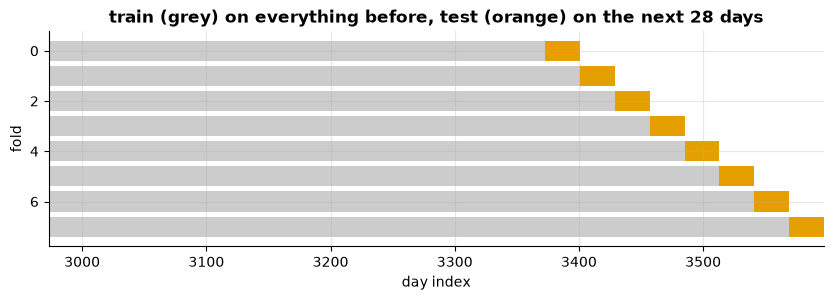

In [3]:
n_folds, horizon = 8, 28
initial = len(daily) - n_folds * horizon
splits = list(ev.expanding_window_splits(len(daily), initial=initial, horizon=horizon))
fig, ax = plt.subplots(figsize=(10, 2.8))
for k, s in enumerate(splits):
    ax.barh(k, s.train.stop - s.train.start, left=s.train.start, color="0.8")
    ax.barh(k, s.test.stop - s.test.start, left=s.test.start, color=viz.PALETTE[1])
ax.set(xlim=(initial - 400, len(daily)), xlabel="day index", ylabel="fold",
       title="train (grey) on everything before, test (orange) on the next 28 days")
ax.invert_yaxis()

## A backtest of five forecasters

`ev.backtest` refits a forecaster on every fold. Four baselines from the toolbox, and the
SARIMA of chapter 4 fitted on the two years before each cut.

In [4]:
def sarima(history, h):
    fit = SARIMAX(history.iloc[-730:].asfreq("D"), order=(1, 0, 1),
                  seasonal_order=(1, 1, 1, 7)).fit(disp=False)
    return fit.forecast(h).to_numpy()

forecasters = {
    "mean": baselines.mean,
    "naive": baselines.naive,
    "drift": baselines.drift,
    "seasonal naive": baselines.seasonal_naive(7),
    "SARIMA": sarima,
}
folds = {name: ev.backtest(daily, f, initial=initial, horizon=horizon)["score"]
         for name, f in forecasters.items()}
per_fold = pd.DataFrame(folds)
per_fold.round(1)

,mean,naive,drift,seasonal naive,SARIMA
0,28.6,23.0,23.0,29.4,24.3
1,27.9,32.2,32.4,9.9,13.2
2,24.5,36.8,37.0,10.5,12.7
3,22.7,37.5,37.6,20.1,11.0
4,24.3,31.8,31.9,14.0,12.6
5,20.4,23.4,23.4,16.5,11.9
6,22.5,32.6,32.7,9.3,10.0
7,21.1,39.5,39.6,22.4,10.9


## Reporting it honestly

Three habits, in this order:

1. **A baseline next to every score.** *Skill* = 1 − MAE / MAE(baseline): 0 means no better than
   "the same weekday last week".
2. **Scale-free where series differ.** MASE divides by the in-sample error of the seasonal
   naive; below 1 beats it.
3. **An interval, not a point.** Eight folds are eight draws. The bootstrap over folds says how
   sure the mean is.

In [5]:
rows = []
base = per_fold["seasonal naive"].mean()
train_all = daily.iloc[:initial]
for name in per_fold:
    est, lo, hi = ev.bootstrap_ci(per_fold[name], n_boot=2000, seed=5)
    rows.append({"model": name, "MAE": est, "95% low": lo, "95% high": hi,
                 "skill vs seasonal naive": ev.skill(est, base),
                 "MASE": est / np.mean(np.abs(train_all.diff(7).dropna()))})
report = pd.DataFrame(rows).set_index("model").sort_values("MAE")
report.round(2)

,MAE,95% low,95% high,skill vs seasonal naive,MASE
model,,,,,
SARIMA,13.31,11.19,16.76,0.19,1.18
seasonal naive,16.53,12.30,21.67,0.00,1.46
mean,23.99,22.24,25.98,-0.45,2.12
naive,32.11,27.80,35.86,-0.94,2.84
drift,32.20,27.87,35.98,-0.95,2.85


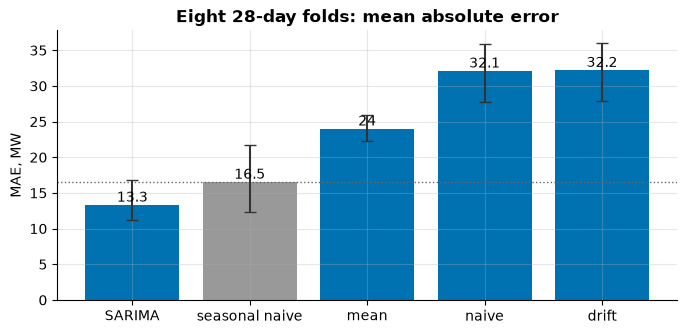

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.5))
viz.bar_scores(report["MAE"].to_dict(), baseline="seasonal naive", ax=ax, unit="MAE, MW",
               title="Eight 28-day folds: mean absolute error")
ax.errorbar(range(len(report)), report["MAE"],
            yerr=[report["MAE"] - report["95% low"], report["95% high"] - report["MAE"]],
            fmt="none", ecolor="0.2", capsize=4);

The seasonal naive is a hard baseline on a series this seasonal, and the mean, the naive and
the drift lose to it badly: none of them knows the week. SARIMA is better on average (positive
skill), but its interval overlaps the baseline's: on eight folds that is a lead, not a proof.
Note also that the seasonal naive's MASE is above 1 -- the test months were harder than the
average week of the training years, which is exactly what MASE is there to show.

## What to remember

- Never shuffle a time series to evaluate a forecast. Fit on the past, test on the future.
- Use many folds; report the mean with an interval.
- Always report the baseline: a score alone is not a result.

## Exercises

1. Use 7-day folds instead of 28. Does the ranking change?
2. Add a forecaster that averages the seasonal naive of the last four weeks.
3. Replace SARIMA's fixed two-year window with all the history. Better or worse?

**Next:** [Chapter 6 · Learned forecasters](06-learned-forecasters.ipynb)